# CNN Development on a Custom Dataset
## CVPR Mid Assignment
**Student ID:** 23-50117-1  
**Dataset:** Hugging Face Beans (3 classes)  
**Framework:** PyTorch


## 1. Objective and dataset description
We classify bean-leaf images into `angular_leaf_spot`, `bean_rust`, and `healthy` using a custom CNN. The public Hugging Face Beans dataset provides train, validation, and test splits. Training data is used to learn parameters, validation data to select the best checkpoint, and test data only for final evaluation. Augmentation is applied only to training images to avoid data leakage.

## 2. Import libraries and reproducibility
PyTorch builds and trains the CNN; Hugging Face `datasets` loads the data; scikit-learn computes metrics; Matplotlib and Seaborn visualize results.

In [ ]:
!pip -q install datasets torchinfo scikit-learn seaborn

In [ ]:
import os, random, copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from datasets import load_dataset
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, classification_report, confusion_matrix

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__, "| Device:", device)

PyTorch: 2.14.1+cpu | Device: cpu


## 3. Load and explore dataset
We inspect split sizes and class names before training. The label names are read from the dataset metadata rather than manually assumed.

In [ ]:
from datasets import load_dataset

dataset = load_dataset("AI-Lab-Makerere/beans")

print(dataset)
print("Splits:", list(dataset.keys()))

class_names = dataset["train"].features["labels"].names
num_classes = len(class_names)

print("Class names:", class_names)
print("Number of classes:", num_classes)

DatasetDict({
    train: Dataset({
        features: ['image_file_path', 'image', 'labels'],
        num_rows: 1034
    })
    validation: Dataset({
        features: ['image_file_path', 'image', 'labels'],
        num_rows: 133
    })
    test: Dataset({
        features: ['image_file_path', 'image', 'labels'],
        num_rows: 128
    })
})
Splits: ['train', 'validation', 'test']
Class names: ['angular_leaf_spot', 'bean_rust', 'healthy']
Number of classes: 3


### 3.1 Sample image visualization
This verifies that images and labels are loaded correctly.

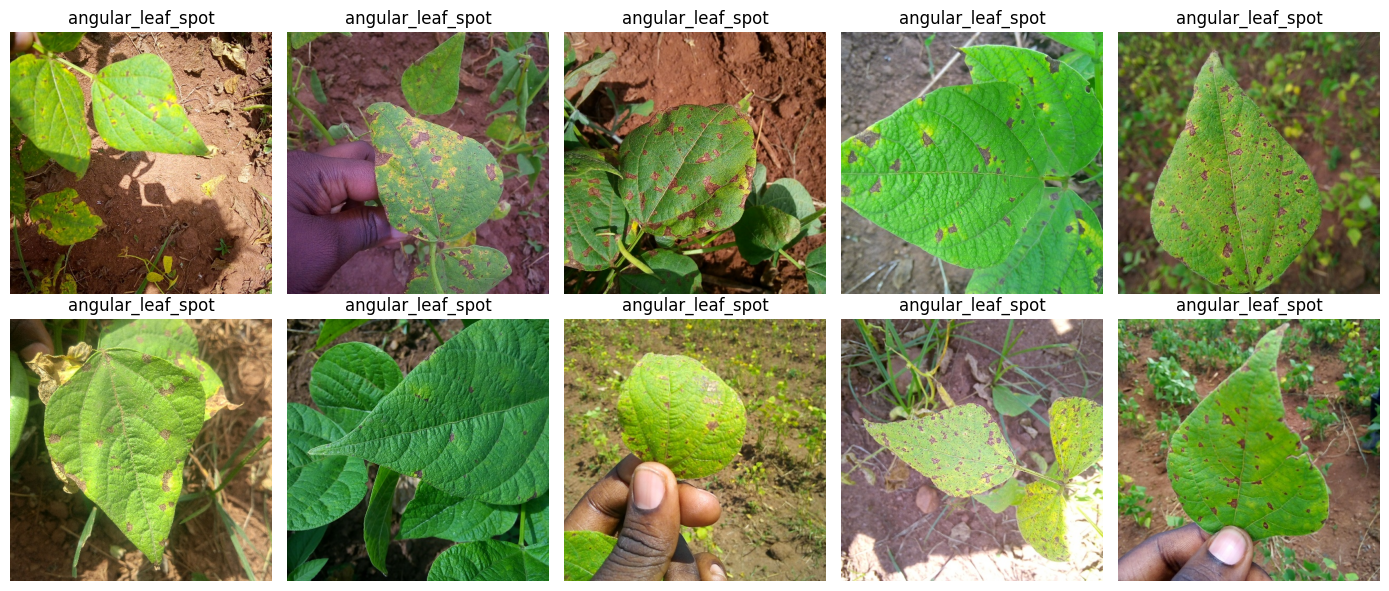

In [ ]:
fig, axes = plt.subplots(2, 5, figsize=(14, 6))
for ax, i in zip(axes.flat, range(10)):
    item = dataset["train"][i]
    ax.imshow(item["image"].convert("RGB"))
    ax.set_title(class_names[int(item["labels"])])
    ax.axis("off")
plt.tight_layout(); plt.show()

## 4. Preprocessing and augmentation
Images are resized to 128×128, converted to tensors, and normalized using mean and standard deviation 0.5. Training-only horizontal flips and small rotations provide augmentation. Validation and test transforms are deterministic.

In [ ]:
IMAGE_SIZE, BATCH_SIZE = 128, 32
NUM_WORKERS = 2 if os.name != "nt" else 0
train_tfms = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize([0.5]*3, [0.5]*3)
])
eval_tfms = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize([0.5]*3, [0.5]*3)
])

class BeansTorchDataset(Dataset):
    def __init__(self, split, transform):
        self.split, self.transform = split, transform
    def __len__(self):
        return len(self.split)
    def __getitem__(self, index):
        row = self.split[index]
        image = row["image"].convert("RGB")
        return self.transform(image), int(row["labels"])

train_ds = BeansTorchDataset(dataset["train"], train_tfms)
val_ds = BeansTorchDataset(dataset["validation"], eval_tfms)
test_ds = BeansTorchDataset(dataset["test"], eval_tfms)
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available())
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available())
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available())
print("Batches:", len(train_loader), len(val_loader), len(test_loader))
xb, yb = next(iter(train_loader))
print("Image batch:", xb.shape, "| Label batch:", yb.shape)

Batches: 33 5 4
Image batch: torch.Size([32, 3, 128, 128]) | Label batch: torch.Size([32])


## 5. Custom CNN architecture
Three convolutional blocks use 3×3 convolution, Batch Normalization, ReLU, and 2×2 max pooling. Channels increase 32→64→128 to learn increasingly rich features. Adaptive average pooling produces a fixed-size feature vector. Dropout (0.4) regularizes the classifier. The final layer outputs three logits. Softmax is intentionally omitted because `CrossEntropyLoss` handles the required log-softmax internally.

In [ ]:
class CustomCNN(nn.Module):
    def __init__(self, num_classes=3):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1), nn.BatchNorm2d(32),
            nn.ReLU(inplace=True), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64),
            nn.ReLU(inplace=True), nn.MaxPool2d(2),
            nn.Conv2d(64, 128, 3, padding=1), nn.BatchNorm2d(128),
            nn.ReLU(inplace=True), nn.MaxPool2d(2),
            nn.AdaptiveAvgPool2d((1, 1))
        )
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Dropout(0.4), nn.Linear(128, num_classes)
        )
    def forward(self, x):
        return self.classifier(self.features(x))

model = CustomCNN(num_classes).to(device)
print(model)

CustomCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU(inplace=True)
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU(inplace=True)
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (12): AdaptiveAvgPool2d(output_size=(1, 1))
  )
  (classifier): Sequential(
    (0): Flatten(st

### 5.1 Detailed architecture summary
The summary reports layer output shapes and parameter counts. The fallback still reports the model and trainable parameter count if `torchinfo` cannot run.

In [ ]:
try:
    from torchinfo import summary
    summary(model, input_size=(1, 3, IMAGE_SIZE, IMAGE_SIZE), device=str(device))
except Exception as e:
    print("torchinfo summary unavailable:", e)
    print(model)
print("Total parameters:", f"{sum(p.numel() for p in model.parameters()):,}")
print("Trainable parameters:", f"{sum(p.numel() for p in model.parameters() if p.requires_grad):,}")

Total parameters: 94,083
Trainable parameters: 94,083


## 6. Training configuration and hyperparameters
| Setting | Value | Rationale |
|---|---:|---|
| Image size | 128×128 | Consistent, manageable input |
| Batch size | 32 | Practical memory/gradient balance |
| Epochs | 15 | Initial training budget; monitor validation |
| Optimizer | Adam | Adaptive parameter updates |
| Learning rate | 0.001 | Common Adam starting point |
| Loss | CrossEntropyLoss | Multi-class classification |
| Weight decay | 0.0001 | Regularization |
| Dropout | 0.4 | Helps limit overfitting |

The best checkpoint is selected using validation loss, never test accuracy.

In [ ]:
EPOCHS, LEARNING_RATE, WEIGHT_DECAY = 15, 0.001, 1e-4
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=2)

## 7. Training loop with validation
Each epoch performs forward propagation, loss calculation, backpropagation, and optimizer updates on training batches. Validation runs in evaluation mode without gradients. Average loss and accuracy are recorded. The weights with the lowest validation loss are saved.

In [ ]:
def run_epoch(model, loader, criterion, optimizer=None):
    training = optimizer is not None
    model.train() if training else model.eval()
    total_loss, targets_all, preds_all = 0.0, [], []
    for inputs, targets in loader:
        inputs, targets = inputs.to(device), targets.to(device)
        if training: optimizer.zero_grad()
        with torch.set_grad_enabled(training):
            outputs = model(inputs)
            loss = criterion(outputs, targets)
            if training:
                loss.backward()
                optimizer.step()
        total_loss += loss.item() * inputs.size(0)
        targets_all.extend(targets.detach().cpu().numpy())
        preds_all.extend(outputs.argmax(1).detach().cpu().numpy())
    return total_loss / len(loader.dataset), accuracy_score(targets_all, preds_all)

history = {"train_loss": [], "val_loss": [], "train_accuracy": [], "val_accuracy": []}
best_val_loss = float("inf")
best_state = copy.deepcopy(model.state_dict())
os.makedirs("outputs", exist_ok=True)

for epoch in range(EPOCHS):
    tr_loss, tr_acc = run_epoch(model, train_loader, criterion, optimizer)
    va_loss, va_acc = run_epoch(model, val_loader, criterion)
    scheduler.step(va_loss)
    for key, value in [("train_loss", tr_loss), ("val_loss", va_loss),
                       ("train_accuracy", tr_acc), ("val_accuracy", va_acc)]:
        history[key].append(value)
    if va_loss < best_val_loss:
        best_val_loss = va_loss
        best_state = copy.deepcopy(model.state_dict())
        torch.save(best_state, "outputs/best_beans_cnn.pth")
    print(f"Epoch {epoch+1:02d}/{EPOCHS} | train loss {tr_loss:.4f}, acc {tr_acc:.4f} | val loss {va_loss:.4f}, acc {va_acc:.4f} | lr {optimizer.param_groups[0]['lr']:.6f}")

model.load_state_dict(best_state)
print("Best validation loss:", round(best_val_loss, 4))

Epoch 01/15 | train loss 0.8739, acc 0.6103 | val loss 0.7740, acc 0.6391 | lr 0.001000
Epoch 02/15 | train loss 0.7535, acc 0.6915 | val loss 0.6429, acc 0.7444 | lr 0.001000
Epoch 03/15 | train loss 0.7203, acc 0.6992 | val loss 0.8441, acc 0.6165 | lr 0.001000
Epoch 04/15 | train loss 0.6801, acc 0.7157 | val loss 0.6407, acc 0.7068 | lr 0.001000
Epoch 05/15 | train loss 0.6418, acc 0.7273 | val loss 0.6684, acc 0.7594 | lr 0.001000
Epoch 06/15 | train loss 0.6651, acc 0.7157 | val loss 0.5546, acc 0.7444 | lr 0.001000
Epoch 07/15 | train loss 0.6153, acc 0.7273 | val loss 0.5712, acc 0.7594 | lr 0.001000
Epoch 08/15 | train loss 0.6030, acc 0.7447 | val loss 0.5867, acc 0.7368 | lr 0.001000
Epoch 09/15 | train loss 0.5651, acc 0.7524 | val loss 0.5955, acc 0.7519 | lr 0.000500
Epoch 10/15 | train loss 0.5587, acc 0.7689 | val loss 0.5126, acc 0.7970 | lr 0.000500
Epoch 11/15 | train loss 0.5503, acc 0.7785 | val loss 0.5245, acc 0.7895 | lr 0.000500
Epoch 12/15 | train loss 0.5104,

## 8. Training and validation curves
A widening gap between training and validation curves can indicate overfitting. If both accuracies remain low, the model may be underfitting.

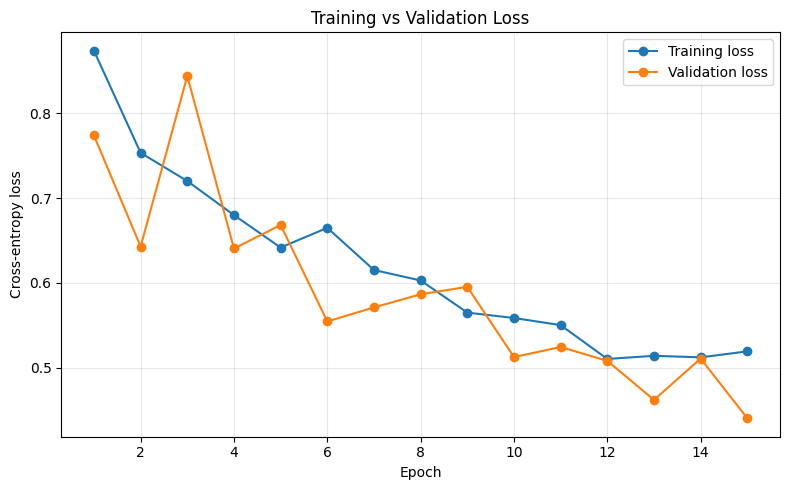

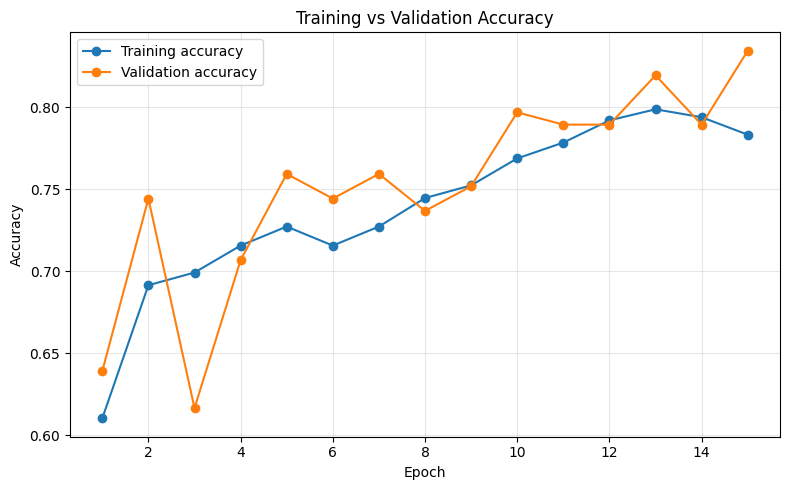

In [ ]:
epochs = range(1, len(history["train_loss"]) + 1)
plt.figure(figsize=(8, 5))
plt.plot(epochs, history["train_loss"], marker="o", label="Training loss")
plt.plot(epochs, history["val_loss"], marker="o", label="Validation loss")
plt.xlabel("Epoch"); plt.ylabel("Cross-entropy loss")
plt.title("Training vs Validation Loss"); plt.legend(); plt.grid(alpha=.3)
plt.tight_layout(); plt.savefig("outputs/loss_curve.png", dpi=150); plt.show()

plt.figure(figsize=(8, 5))
plt.plot(epochs, history["train_accuracy"], marker="o", label="Training accuracy")
plt.plot(epochs, history["val_accuracy"], marker="o", label="Validation accuracy")
plt.xlabel("Epoch"); plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy"); plt.legend(); plt.grid(alpha=.3)
plt.tight_layout(); plt.savefig("outputs/accuracy_curve.png", dpi=150); plt.show()

## 9. Test-set evaluation
The best validation checkpoint is evaluated once on the untouched test split. Accuracy, macro precision, macro recall, and macro F1 are reported. Macro averaging weights each class equally.

In [ ]:
model.eval()
y_true, y_pred = [], []
with torch.no_grad():
    for inputs, targets in test_loader:
        outputs = model(inputs.to(device))
        y_true.extend(targets.numpy())
        y_pred.extend(outputs.argmax(1).cpu().numpy())

test_acc = accuracy_score(y_true, y_pred)
precision, recall, f1, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
print(f"Test accuracy: {test_acc:.4f} ({test_acc*100:.2f}%)")
print(f"Macro precision: {precision:.4f}")
print(f"Macro recall: {recall:.4f}")
print(f"Macro F1-score: {f1:.4f}")
print(classification_report(y_true, y_pred, target_names=class_names, zero_division=0))

Test accuracy: 0.7734 (77.34%)
Macro precision: 0.7813
Macro recall: 0.7743
Macro F1-score: 0.7663
                   precision    recall  f1-score   support

angular_leaf_spot       0.70      0.91      0.79        43
        bean_rust       0.77      0.53      0.63        43
          healthy       0.88      0.88      0.88        42

         accuracy                           0.77       128
        macro avg       0.78      0.77      0.77       128
     weighted avg       0.78      0.77      0.77       128



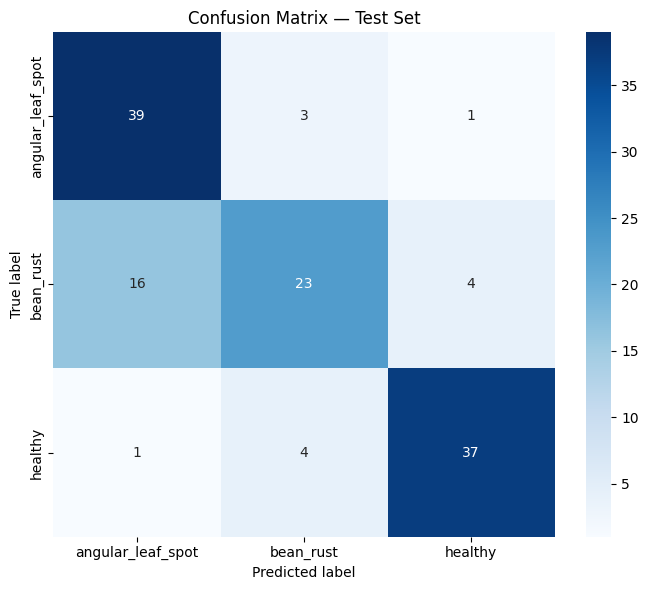

In [ ]:
cm = confusion_matrix(y_true, y_pred, labels=list(range(num_classes)))
plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted label"); plt.ylabel("True label")
plt.title("Confusion Matrix — Test Set")
plt.tight_layout(); plt.savefig("outputs/confusion_matrix.png", dpi=150); plt.show()

## 10. Save model weights
The `.pth` file stores the model state dictionary. If it exceeds 20 MB, keep a local copy rather than uploading it to GitHub, as instructed.

In [ ]:
checkpoint_path = "outputs/best_beans_cnn.pth"
torch.save(model.state_dict(), checkpoint_path)
size_mb = os.path.getsize(checkpoint_path) / (1024**2)
print(f"Saved: {checkpoint_path} ({size_mb:.2f} MB)")
print("Larger than 20 MB — keep local." if size_mb > 20 else "20 MB or smaller — may be uploaded to GitHub.")

Saved: outputs/best_beans_cnn.pth (0.37 MB)
20 MB or smaller — may be uploaded to GitHub.


In [ ]:

# AUTOMATIC ANALYSIS FOR SECTION 11

# 1. Overall test performance
print("===== TEST PERFORMANCE =====")
print(f"Test Accuracy: {test_acc*100:.2f}%")
print(f"Macro Precision: {precision:.4f}")
print(f"Macro Recall: {recall:.4f}")
print(f"Macro F1-score: {f1:.4f}")

# 2. Class-wise performance
report = classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

class_f1 = {
    name: report[name]["f1-score"]
    for name in class_names
}

best_class = max(class_f1, key=class_f1.get)
weakest_class = min(class_f1, key=class_f1.get)

print("\n===== CLASS-WISE ANALYSIS =====")
print("Best performing class:", best_class)
print("Weakest performing class:", weakest_class)
print("Class-wise F1 scores:", class_f1)

# 3. Training and validation loss analysis
train_loss_decreased = history["train_loss"][-1] < history["train_loss"][0]
val_loss_decreased = history["val_loss"][-1] < history["val_loss"][0]

print("\n===== LEARNING CURVE ANALYSIS =====")
print("Training loss decreased:", train_loss_decreased)
print("Validation loss decreased:", val_loss_decreased)

final_gap = abs(
    history["train_accuracy"][-1] -
    history["val_accuracy"][-1]
)

print(f"Final train-validation accuracy gap: {final_gap:.4f}")

# 4. Most confused class pair
cm_analysis = confusion_matrix(
    y_true, y_pred, labels=list(range(num_classes))
)

np.fill_diagonal(cm_analysis, 0)

if cm_analysis.max() > 0:
    i, j = np.unravel_index(
        np.argmax(cm_analysis), cm_analysis.shape
    )
    print("\n===== CONFUSION MATRIX ANALYSIS =====")
    print(f"Most confused pair: {class_names[i]} -> {class_names[j]}")
    print("Number of incorrect predictions:", cm_analysis[i, j])
else:
    print("\nNo incorrect predictions in the test set.")


===== TEST PERFORMANCE =====
Test Accuracy: 77.34%
Macro Precision: 0.7813
Macro Recall: 0.7743
Macro F1-score: 0.7663

===== CLASS-WISE ANALYSIS =====
Best performing class: healthy
Weakest performing class: bean_rust
Class-wise F1 scores: {'angular_leaf_spot': 0.7878787878787878, 'bean_rust': 0.6301369863013698, 'healthy': 0.8809523809523809}

===== LEARNING CURVE ANALYSIS =====
Training loss decreased: True
Validation loss decreased: True
Final train-validation accuracy gap: 0.0512

===== CONFUSION MATRIX ANALYSIS =====
Most confused pair: bean_rust -> angular_leaf_spot
Number of incorrect predictions: 16


## 12. Conclusion and Future Work

In this assignment, a custom Convolutional Neural Network (CNN) was successfully designed and implemented using PyTorch for three-class bean leaf image classification.

The Hugging Face Beans dataset was used, containing three categories: Angular Leaf Spot, Bean Rust, and Healthy. The dataset was divided into training, validation, and testing sets. Image preprocessing techniques, including resizing, normalization, and data augmentation, were applied to improve the model's learning capability.

The CNN architecture consisted of three convolutional blocks with Batch Normalization, ReLU activation, and Max Pooling layers, followed by a fully connected classification layer. The Adam optimizer and Cross-Entropy Loss function were used for model training. Training and validation performance were monitored throughout the epochs to identify the best model.

Finally, the trained model was evaluated using test accuracy, precision, recall, F1-score, and a confusion matrix. Training and validation curves were also generated to analyze the learning behaviour and generalization performance. The best-performing model weights were saved in `.pth` format.

**Future Work:**

- Experiment with deeper CNN architectures to improve feature extraction.
- Perform hyperparameter tuning to identify better learning rates, batch sizes, and dropout values.
- Apply class-weighted loss if class imbalance affects classification performance.
- Explore additional image augmentation techniques.
- Compare the custom CNN with transfer-learning models such as ResNet to evaluate potential performance improvements.

Overall, this assignment demonstrates the complete implementation of a deep learning-based image classification pipeline, from dataset preparation to model evaluation and saving.

Suggested repository: `CNN-Assignment/CNN_StudentID.ipynb`, `README.md`, and `outputs/`.

Dataset: https://huggingface.co/datasets/beans  
PyTorch: https://pytorch.org/docs/stable/index.html